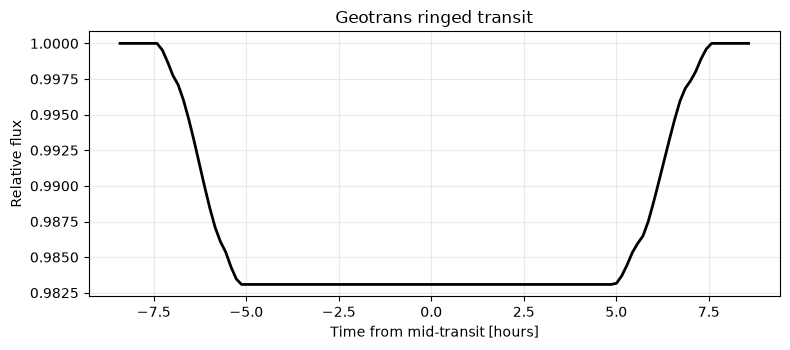

In [4]:
# PhotoRing Simulator (https://seap-udea.github.io/apps/photoring-simulator) → geotrans (Zuluaga et al. 2015)
# Generated from the current photoring-simulator configuration.
# Downloads geotrans.py from the PRisma pipeline if not already present.
from urllib import request
request.urlretrieve("https://raw.githubusercontent.com/seap-udea/PRisma/master/pipeline/geotrans/geotrans.py","geotrans.py")
import geotrans as gt
import matplotlib.pyplot as plt
import numpy as np
from scipy.constants import G

# Constants
deg = np.pi / 180 # factor from degrees to radians
rad = 1 / deg
HOUR = 3600.0  # seconds in an hour
DAY = 86400.0 # seconds in a day

# System parameters (default: saturn-sun preset)
p  = 0.084 # planet radius [R*]
fi = 1.58 # inner ring radius [Rp]
fe = 2.35 # outer ring radius [Rp]
tilt = 25.0 # sky-plane position angle / tilt [degrees]
ir = 55.0 # sky-plane ring inclination [degrees]
b = 0.25 # impact parameter [R*]
alpha = np.exp(-1) # ring transmission; exp(-1) → tau_normal = 1
mstar = 1.0 # M* [M_sun]
rstar = 1.0 # R* [R_sun]
porb = 365.25  # Porb [days]

# Stellar density and derived orbital geometry
rho_gcc = 1408.0 * mstar / rstar**3 / 1e3  # stellar density [g/cm³], 1408 kg/m³ is solar
tau = -np.log(alpha) # normal optical depth
a_rs = (G * rho_gcc * 1e3 * (porb * DAY)**2 / (3 * np.pi))**(1/3) # a/R*
iorb = np.arccos(b / a_rs)

# Sky-plane → intrinsic orbital frame conversion
# geotrans uses intrinsic angles (ir_3d, phir_3d) relative to the orbital plane.
# apparent_to_intrinsic converts sky-plane (ir, tilt) in degrees given iorb.
ir_3d, phir_3d = gt.apparent_to_intrinsic(ir, tilt, iorb)

# Initialize geotrans ringed system
system = dict(
    rhotrue=rho_gcc, P=porb, b=b, ep=0., wp=0.,
    p=p, fp=0., fi=fi, fe=fe, ir=ir_3d, phir=phir_3d, tau=tau,
    c1=0., c2=0. # c1=c2=0: uniform disk (no limb darkening)
)
S = gt.RingedSystem(system)  

# Contact times from geotrans
tcen, t1_raw, t2_raw, t3_raw, t4_raw = gt.contactTimes(S)
t1 = -(t4_raw - tcen) / HOUR
t2 = -(t3_raw - tcen) / HOUR
t3 = -(t2_raw - tcen) / HOUR
t4 = -(t1_raw - tcen) / HOUR

# Transit depth and observed stellar density
Ar_mid = gt.ringedPlanetArea(S)

# Light curve
ts_s = np.linspace(tcen + t1*HOUR - 1*HOUR, tcen + t4*HOUR + 1*HOUR, 120)
flux = np.array([gt.fluxLimbTime(t, Ar_mid, S) for t in ts_s])
ts_h = (ts_s - tcen) / HOUR # Times in hours relative to mid-transit

# Plot
fig, ax = plt.subplots(figsize=(8, 3.6))
ax.plot(ts_h, flux, color="k", lw=2)
ax.set_xlabel("Time from mid-transit [hours]")
ax.set_ylabel("Relative flux")
ax.set_title(f"Geotrans ringed transit")
ax.grid(True, alpha=0.25)
plt.tight_layout()
plt.show()